In [1]:
!pip install tensorflow scikit-learn matplotlib seaborn

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [6]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [7]:
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.19.0


In [8]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [9]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Unique labels:", np.unique(y_train))
print("Class counts:")
print(np.bincount(y_train))

Minimum pixel value: 0
Maximum pixel value: 255
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Class counts:
[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


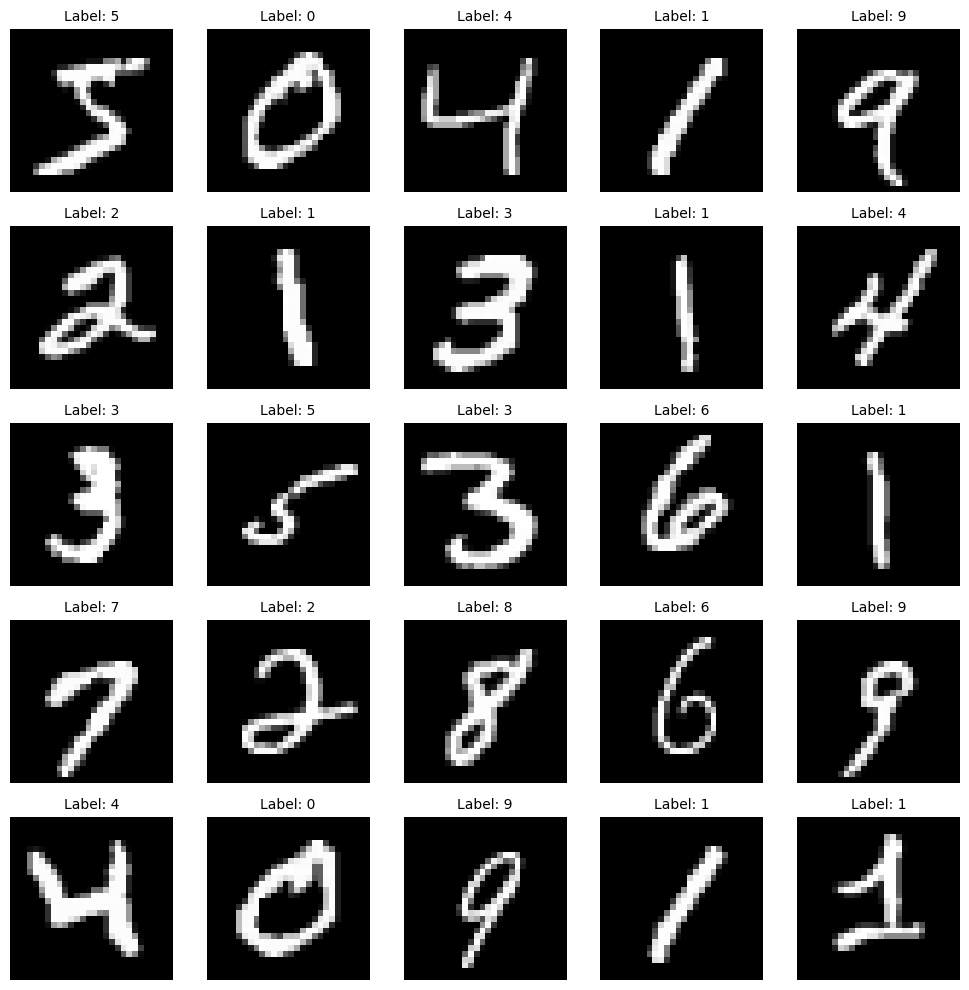

In [10]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}", fontsize=10)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("new manimum:", X_train.min())
print("new maximum:", X_train.max())

new manimum: 0.0
new maximum: 1.0


In [12]:
model = Sequential([
    Input(shape=(28,28)),
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])


In [13]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [16]:
earlystopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

In [17]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    callbacks=[earlystopping],
    verbose=1
)

Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9036 - loss: 0.3295 - val_accuracy: 0.9553 - val_loss: 0.1560
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9518 - loss: 0.1594 - val_accuracy: 0.9662 - val_loss: 0.1137
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9637 - loss: 0.1185 - val_accuracy: 0.9701 - val_loss: 0.0978
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9709 - loss: 0.0972 - val_accuracy: 0.9732 - val_loss: 0.0887
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9748 - loss: 0.0821 - val_accuracy: 0.9732 - val_loss: 0.0855
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9772 - loss: 0.0719 - val_accuracy: 0.9751 - val_loss: 0.0833
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9804 - loss: 0.0611 - val_accuracy: 0.9766 - val_loss: 0.0784
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9820 - loss: 0.0548 - 

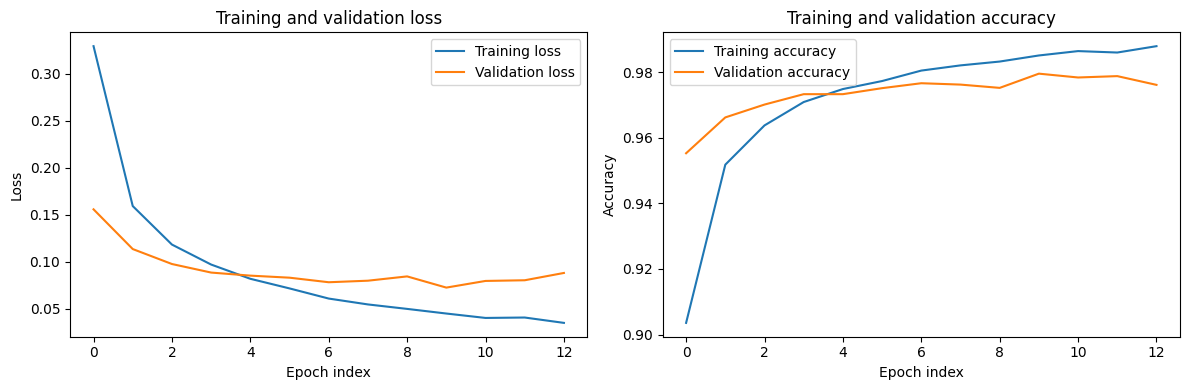

In [18]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epoch index")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

Test loss: 0.0716
Test accuracy: 97.86%


In [23]:
y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

print("Probablity shape:", y_prob.shape)
print("Prediction shape:", y_pred.shape)


Probablity shape: (10000, 10)
Prediction shape: (10000,)


In [24]:
print("First predicted digit:", y_pred[0])
print("First actual digit:", y_test[0])

First predicted digit: 7
First actual digit: 7


In [25]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.2%}\n")

digit_names = [str(digit) for digit in range(10)]

print(classification_report(
    y_test,
    y_pred,
    target_names=digit_names,
    digits=4
))

Accuracy: 97.86%

              precision    recall  f1-score   support

           0     0.9768    0.9888    0.9828       980
           1     0.9877    0.9903    0.9890      1135
           2     0.9805    0.9738    0.9772      1032
           3     0.9773    0.9822    0.9798      1010
           4     0.9795    0.9725    0.9760       982
           5     0.9852    0.9731    0.9791       892
           6     0.9812    0.9812    0.9812       958
           7     0.9729    0.9786    0.9758      1028
           8     0.9673    0.9723    0.9698       974
           9     0.9771    0.9713    0.9742      1009

    accuracy                         0.9786     10000
   macro avg     0.9786    0.9784    0.9785     10000
weighted avg     0.9786    0.9786    0.9786     10000



<Figure size 900x700 with 0 Axes>

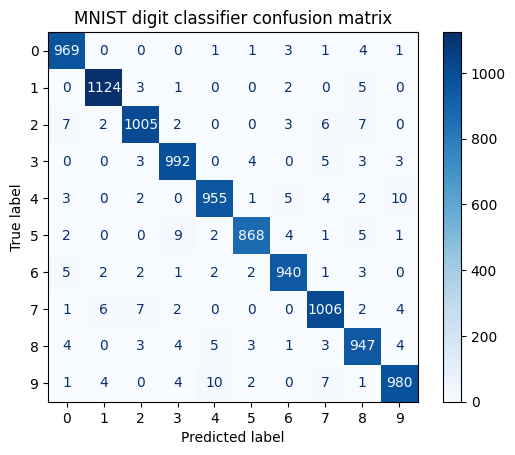

In [26]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=digit_names
).plot(
    values_format="d",
    cmap="Blues"
)

plt.title("MNIST digit classifier confusion matrix")
plt.show()

Number of misclassified test images: 214


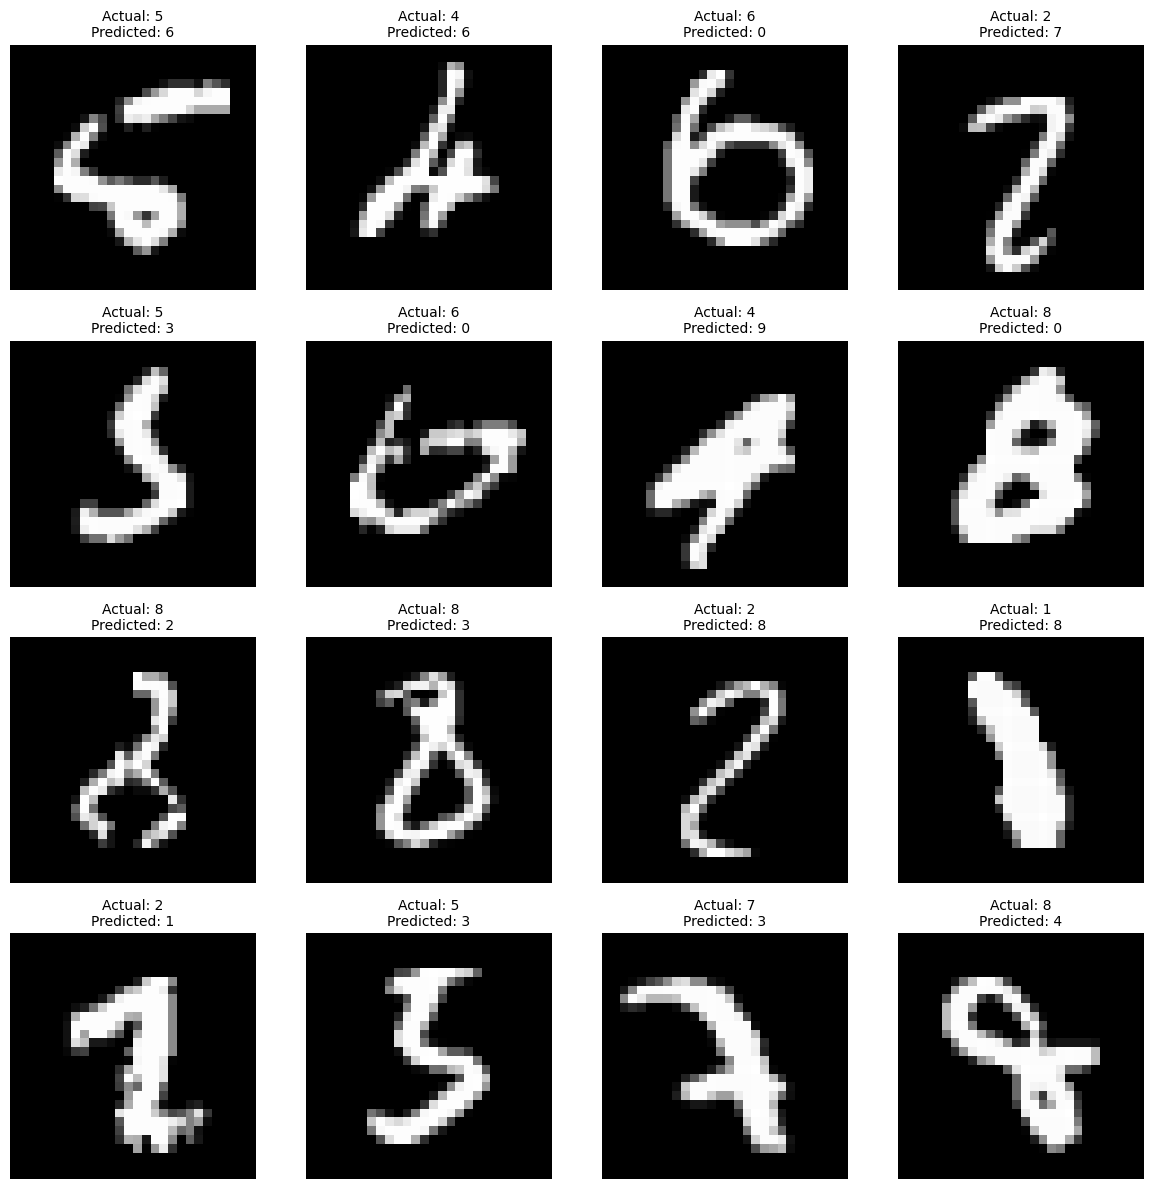

In [27]:
wrong_indices = np.where(y_pred != y_test)[0]

print(f"Number of misclassified test images: {len(wrong_indices)}")

plt.figure(figsize=(12, 12))

for i, idx in enumerate(wrong_indices[:16]):
    plt.subplot(4, 4, i + 1)
    plt.imshow(X_test[idx], cmap="gray")
    plt.title(
        f"Actual: {y_test[idx]}\nPredicted: {y_pred[idx]}",
        fontsize=10
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
model.save("mnist_digit_classifier.keras")

print("Model saved successfully.")

Model saved successfully.


In [33]:
loaded_model = keras.models.load_model("mnist_digit_classifier.keras")

image_index = 4

single_image = X_test[image_index:image_index + 1]

probabilities = loaded_model.predict(single_image, verbose=0)[0]
predicted_digit = probabilities.argmax()

print("Predicted digit:", predicted_digit)
print("Actual digit:", y_test[image_index])

print("\nClass probabilities:")
for digit, probability in enumerate(probabilities):
    print(f"Digit {digit}: {probability:.4f}")

Predicted digit: 4
Actual digit: 4

Class probabilities:
Digit 0: 0.0000
Digit 1: 0.0000
Digit 2: 0.0000
Digit 3: 0.0000
Digit 4: 0.9958
Digit 5: 0.0000
Digit 6: 0.0000
Digit 7: 0.0000
Digit 8: 0.0000
Digit 9: 0.0042


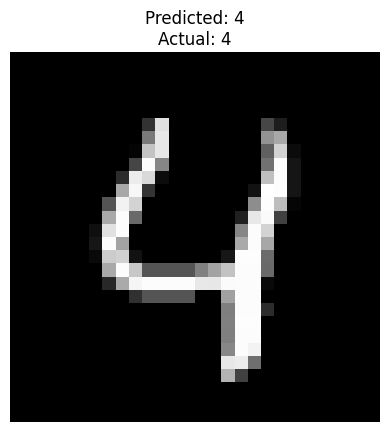

In [34]:
plt.figure()
plt.imshow(X_test[image_index], cmap="gray")
plt.title(
    f"Predicted: {predicted_digit}\nActual: {y_test[image_index]}"
)
plt.axis("off")
plt.show()